Note: you may need to restart the kernel to use updated packages.


  sex famsize  studytime activities romantic  freetime  Dalc  G3
0   F     GT3          2         no       no         3     1   6
1   F     GT3          2         no       no         3     1   6
2   F     LE3          2         no       no         3     2  10
3   F     GT3          3        yes      yes         2     1  15
4   F     GT3          2         no       no         3     1  10
sex ['F', 'M']
famsize ['GT3', 'LE3']
studytime [1, 2, 3, 4]
activities ['no', 'yes']
romantic ['no', 'yes']
freetime [1, 2, 3, 4, 5]
Dalc [1, 2, 3, 4, 5]
G3 [0, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


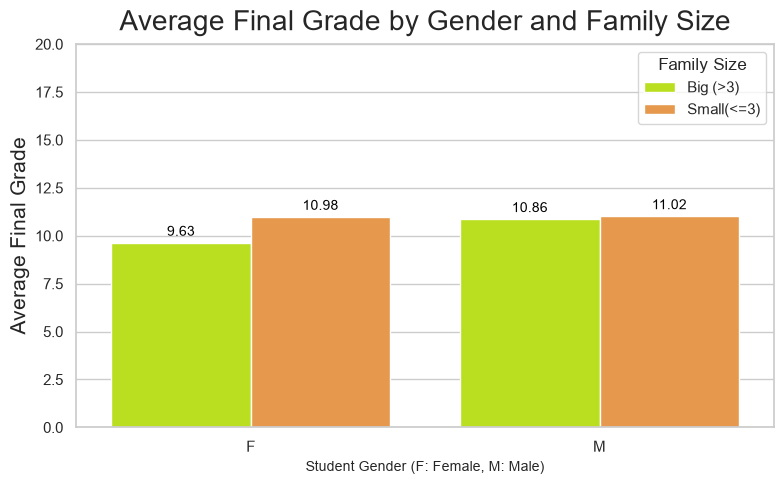

In [122]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
np.random.seed(999)

# Read the CSV that sits in the same folder as this notebook
df = pd.read_csv("student-mat-selected-columns.csv")

print(df.head())

for col in df.columns:
    print(col, sorted(df[col].unique().tolist()))

#Analyzes the impact of family size on student performance by gender
def female_domestic_burden(dataframe):

    #Set up the canvas figure dimensions and apply a clean white grid background theme
    plt.figure(figsize=(8, 5))
    sns.set_theme(style="whitegrid")

    #Create an explicit color mapping dictionary to ensure deterministic colors for each family size category
    cores_explicitas = {'GT3': "#CCFF00", 'LE3': '#FF9933'}  # GT3 = green, LE3 = orange

    # Draw the grouped bar chart using explicit order and styling parameters
    ax = sns.barplot(
        x='sex',                                  # Horizontal axis: Student gender (F and M
        y='G3',                                   # Vertical axis: Final grade (G3) mean value
        hue='famsize',                            # Group/split bars by family size category
        hue_order=['GT3', 'LE3'],                 # Force strict order: GT3 first (green), LE3 second (orange)
        data=dataframe,                           # Source dataframe
        palette=cores_explicitas,                 # Apply the predefined custom color dictionary
        errorbar=None                             # Remove confidence interval error bars for a cleaner look
    )

    #Customize chart titles, axis labels, legend properties, and vertical limits
    plt.title('Average Final Grade by Gender and Family Size', fontsize=20, pad=10)
    plt.xlabel('Student Gender (F: Female, M: Male)', fontsize=10)
    plt.ylabel('Average Final Grade', fontsize=15)
    plt.legend(title='Family Size', labels=['Big (>3)', 'Small(<=3)'])
    plt.ylim(0,20)

    #Iterate through each individual bar rectangle (patch) to annotate exact mean values on top
    for p in ax.patches:
        # Retrieve the numeric height of the current bar (which represents the G3 mean score)
        height = p.get_height()

        # Defensive programming: only proceed if the bar has a positive, valid height
        if height > 0:
            # Annotate the formatted value directly above the bar center
            ax.annotate(
                f'{height:.2f}',                                      # Format height as a string with exactly 2 decimal places
                (p.get_x() + p.get_width() / 2., height),             # Coordinates: X is the exact horizontal center of the bar, Y is its top height
                ha='center',                                          # Horizontal alignment: center text relative to the X coordinate
                va='bottom',                                          # Vertical alignment: anchor the bottom of the text to the bar's top edge
                fontsize=10,                                          # Text font size
                color='black',                                        # Text color
                xytext=(0, 3),                                        # Pixel offset: shift text 3 points upwards so it doesn't collide with the bar
                textcoords='offset points'                            # Specify that xytext is measured in points
            )
    #Adjust layout
    plt.tight_layout()
    plt.show()


female_domestic_burden(df)

# que fatores se associam mais ao insucesso a Matemática?
#female_domestic_burden: rapariga tem notas mais baixas porque ajuda mais em casa (sex,famsize,G3)
#dating_impact: as notas de um aluno sem habitos de estudar a namorar são pessimas(romantic, G3, study)
